In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

data = {
     "Student": ["Rahul", "Sachin", "Priya", "Amit", "Sneha", "Vikram", "Ananya", "Rohan", "Deepika", "Arjun", "Kiran", "Aditya", "Neha", "Sanjay", "Pooja"],
     "Study_Hours": [2, 3, 4, 5, 4, 6, 5, 3, 4, 5, 6, 4, 5, 3, 3]
      }

df = pd.DataFrame(data)

print("Original Dataset")
display(df)

Original Dataset


,Student,Study_Hours
0,Rahul,2
1,Sachin,3
2,Priya,4
3,Amit,5
4,Sneha,4
5,Vikram,6
6,Ananya,5
7,Rohan,3
8,Deepika,4
9,Arjun,5


In [ ]:
df["Study_Hours"].describe()

,Study_Hours
count,15.000000
mean,4.133333
std,1.187234
min,2.000000
25%,3.000000
50%,4.000000
75%,5.000000
max,6.000000


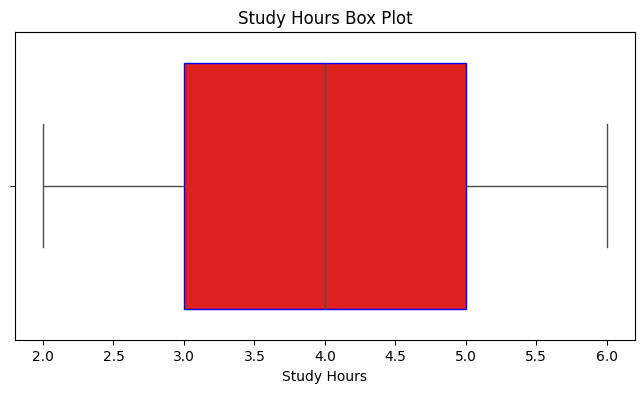

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Study_Hours"], color="red", boxprops=dict(edgecolor="blue"))
plt.title("Study Hours Box Plot")
plt.xlabel("Study Hours")
plt.show()

In [ ]:
Q1=df["Study_Hours"].quantile(0.25)
Q3=df["Study_Hours"].quantile(0.75)
IQR=Q3-Q1
print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)

Q1: 3.0
Q3: 5.0
IQR: 2.0


In [ ]:
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
print("Lower Bound:",lower_bound)
print("Upper Bound:",upper_bound)

Lower Bound: 0.0
Upper Bound: 8.0


In [ ]:
normal_data_points=df[(df["Study_Hours"]>=lower_bound)&(df["Study_Hours"]<=upper_bound)]
print("Normal Data Points")
display(normal_data_points)


Normal Data Points


,Student,Study_Hours
0,Rahul,2
1,Sachin,3
2,Priya,4
3,Amit,5
4,Sneha,4
5,Vikram,6
6,Ananya,5
7,Rohan,3
8,Deepika,4
9,Arjun,5


In [ ]:
outlier_data_points=df[(df["Study_Hours"]<lower_bound)|(df["Study_Hours"]>upper_bound)]
print("Outlier Data Points")
display(outlier_data_points)


Outlier Data Points


,Student,Study_Hours


In [ ]:
df["z_score"]=zscore(df["Study_Hours"])
print("Dataframe with Z-Scores")
display(df)

Dataframe with Z-Scores


,Student,Study_Hours,z_score
0,Rahul,2,-1.859962
1,Sachin,3,-0.988105
2,Priya,4,-0.116248
3,Amit,5,0.755610
4,Sneha,4,-0.116248
5,Vikram,6,1.627467
6,Ananya,5,0.755610
7,Rohan,3,-0.988105
8,Deepika,4,-0.116248
9,Arjun,5,0.755610


In [ ]:
z_outliers=df[
    (df["z_score"]<-3)|(df["z_score"]>3)
]
print("Z-Score Outliers")
display(z_outliers)


Z-Score Outliers


,Student,Study_Hours,z_score


In [ ]:
df_without_outliers=df[
    (df["Study_Hours"]>=lower_bound)&(df["Study_Hours"]<=upper_bound)
]
print("Dataframe without Outliers")
display(df_without_outliers)

Dataframe without Outliers


,Student,Study_Hours,z_score
0,Rahul,2,-1.859962
1,Sachin,3,-0.988105
2,Priya,4,-0.116248
3,Amit,5,0.755610
4,Sneha,4,-0.116248
5,Vikram,6,1.627467
6,Ananya,5,0.755610
7,Rohan,3,-0.988105
8,Deepika,4,-0.116248
9,Arjun,5,0.755610


In [ ]:
df_capped=df.copy()
df_capped["Study_Hours"]=df_capped["Study_Hours"].clip(lower=lower_bound,upper=upper_bound)
print("Dataframe with Capped Values")
display(df_capped)

Dataframe with Capped Values


,Student,Study_Hours,z_score
0,Rahul,2,-1.859962
1,Sachin,3,-0.988105
2,Priya,4,-0.116248
3,Amit,5,0.755610
4,Sneha,4,-0.116248
5,Vikram,6,1.627467
6,Ananya,5,0.755610
7,Rohan,3,-0.988105
8,Deepika,4,-0.116248
9,Arjun,5,0.755610


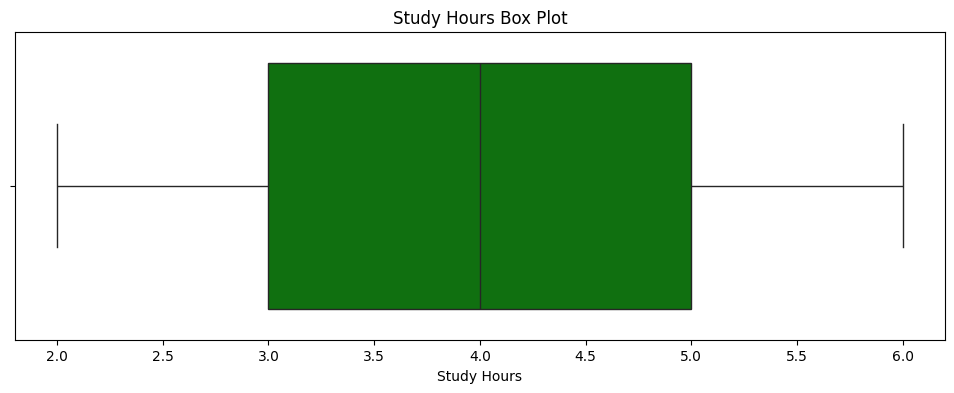

In [ ]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=df_capped["Study_Hours"], color="green")
plt.title("Study Hours Box Plot")
plt.xlabel("Study Hours")
plt.show()